In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math

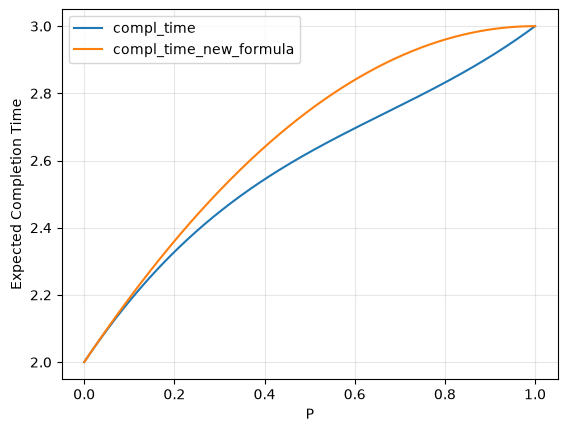

In [3]:
# using T = 1
# calculate for all values of P [0, 1]

T = 1
P_values = np.linspace(0, 1, 1000)
# print(P_values)

compl_time = P_values * 3*T + (1-P_values)* (P_values*2*T + (1-P_values) * (P_values*3*T + (1-P_values)*2*T)) 
# print(compl_time)


compl_time_new_formula = P_values * 3*T + (1-P_values)* (P_values*3*T + (1-P_values) * 2*T) 
# P×3T + (1-P)(P×3T + (1-P)×2T)
# print(compl_time)

# plot values
plt.figure()
plt.plot(P_values, compl_time, label="compl_time")
plt.plot(P_values, compl_time_new_formula, label="compl_time_new_formula")
plt.legend()
plt.title("")
plt.xlabel("P")
plt.ylabel("Expected Completion Time")
plt.grid(alpha=0.3)
plt.savefig("1_expected_time.png")
plt.show()

0.0
0.1
0.2
0.30000000000000004
0.4
0.5
0.6000000000000001
0.7000000000000001
0.8
0.9
1.0
[np.float64(2.0), np.float64(2.1909), np.float64(2.3536), np.float64(2.5092), np.float64(2.6418), np.float64(2.7433), np.float64(2.8411), np.float64(2.9166), np.float64(2.9565), np.float64(2.9887), np.float64(3.0)]


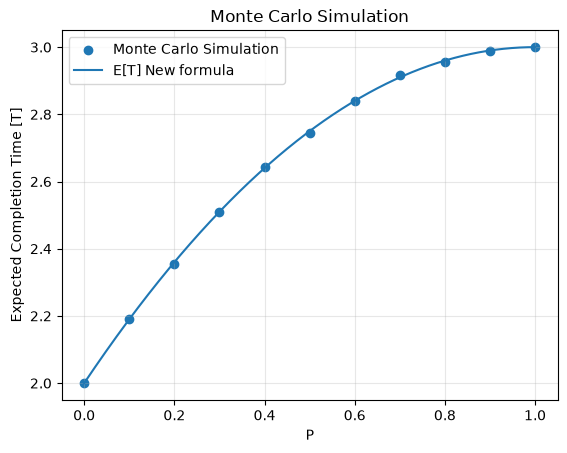

In [4]:

# Monte Carlo Simulation
# output variable: completion time
# input variable: P (keep uniform distribution for now)


def simulate_run(P, T, n_partitions, rng):
    # set W1, W2
    W1_failed = False
    W2_failed = False

    left, right = 0, n_partitions - 1
    round = 0

    while left <= right:
        round += 1

        if not W1_failed and not W2_failed:
            W1_failed = rng.random() < P
            if not W1_failed:
                W2_failed = rng.random() < P

        if not W1_failed: 
            left +=1
        if not W2_failed:
            right -= 1
            
    return round * T


rng = np.random.default_rng(seed=42)
T = 1
P_values2 = np.linspace(0, 1, 11)
runs_per_P = 10_000
mean_times = []


for P in P_values2:
    # run sim many times, random possibility of failing
    print(P)
    times_for_P = []
    for run in range(runs_per_P):
        time = simulate_run(P, T, 3, rng)
        times_for_P.append(time)
    mean_times.append(np.mean(times_for_P))

print(mean_times)
    


# plot values
plt.scatter(P_values2, mean_times, label="Monte Carlo Simulation")
plt.plot(P_values, compl_time_new_formula, label="E[T] New formula")
plt.legend()
plt.title("Monte Carlo Simulation")
plt.xlabel("P")
plt.ylabel("Expected Completion Time [T]")
plt.grid(alpha=0.3)
plt.savefig("2_monte_carlo.png")
plt.show()

In [6]:
def general_2w(t, K, P):
    if t <= math.ceil(K/2):
        return t
    else:
        return P * t + (1-P)*(P * t + (1-P) * general_2w(t-1, K, P))

res = general_2w(3, 3, 0.1)
print(res)


2.1900000000000004
